# Publication-Quality Visualization with Python
## Workshop Code-Along — Python-Only Edition (for Jupyter)

**Instructor:** Yuyan Yi  
**Date:** December 4, 2026

> This code notebook was drafted with assistance from Claude (Anthropic) and reviewed and edited by the instructor prior to teaching.
>
> **This is the Python-only version of the workshop materials**, for attendees using Jupyter without an R kernel available. A separate R Markdown version exists for R-only attendees. A combined Quarto document (R + Python side by side) is also available for anyone running Positron with both languages configured.

## Setup

### Python packages needed

Run this once in a terminal (or a notebook cell with a `!` prefix), using the exact Python environment this notebook's kernel is using:

```bash
pip install pandas numpy matplotlib seaborn lifelines statannotations scipy tableone scikit-learn statsmodels joypy
```

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sets seaborn's default plot style globally (white background with gridlines,
# normal font size) so every chart in the notebook looks consistent without
# re-styling each one.
sns.set_theme(style="whitegrid", font_scale=1.0)

colors = {"Control": "#440154", "Treatment": "#21908C"}

---

## 1. Generate Synthetic Clinical Data

We'll simulate a small clinical trial dataset: patient demographics, a biomarker, treatment arm, a continuous lab outcome, and survival/censoring data. This mirrors the shape of real trial data without using any real patient information.

**Sample size:** 200 simulated patients

| Column | Type | Description |
|---|---|---|
| patient_id | ID | Sequential, e.g. PT-001 to PT-200 |
| arm | Categorical (2 levels) | Control or Treatment, randomly assigned ~50/50 |
| age | Continuous | Normally distributed, mean 58, SD 12 |
| sex | Categorical (2 levels) | Female (52%) / Male (48%) |
| site | Categorical (4 levels) | Site_1-Site_4, randomly assigned (Site_3 has a lower average outcome baked in) |
| smoker | Categorical (3 levels) | Never (50%), Former (30%), Current (20%) |
| biomarker | Continuous | Right-skewed (gamma distribution, shape 2, scale 15) |
| baseline_score | Continuous | Normally distributed, mean 50, SD 10 |
| followup_score | Continuous | Baseline score minus a treatment effect |
| responder / response_label | Binary / Categorical | 1 = responder; higher response rate in Treatment (55%) vs. Control (30%) |
| time_months / event | Continuous / Binary | Simulated time-to-event and event/censoring indicator (65% event rate) |

In [26]:
np.random.seed(42)
n = 200

arm = np.random.choice(["Control", "Treatment"], size=n)
age = np.round(np.random.normal(58, 12, n))
sex = np.random.choice(["Female", "Male"], size=n, p=[0.52, 0.48])
site = np.random.choice(["Site_1", "Site_2", "Site_3", "Site_4"], size=n)
smoker = np.random.choice(["Never", "Former", "Current"], size=n, p=[0.5, 0.3, 0.2])
biomarker = np.random.gamma(shape=2, scale=15, size=n)
baseline_score = np.random.normal(50, 10, n)

# Site-level effect baked in so the ANOVA/pairwise comparisons section has
# something real to find -- Site_3 runs noticeably lower than the others.
site_effect = np.where(site == "Site_3", -9, 0)

treatment_drop = np.where(
    arm == "Treatment",
    np.random.normal(8, 5, n),
    np.random.normal(1, 5, n)
)
followup_score = baseline_score - treatment_drop + site_effect

responder = np.where(
    arm == "Treatment",
    np.random.binomial(1, 0.55, n),
    np.random.binomial(1, 0.30, n)
)
response_label = np.where(responder == 1, "Response", "No Response")

rate = 1 / (24 + np.where(arm == "Treatment", 8, 0) - (age - 58) * 0.2)
time_months = np.maximum(1, np.random.exponential(1 / rate))
event = np.random.binomial(1, 0.65, n)

clinical_py = pd.DataFrame({
    "patient_id": [f"PT-{i+1:03d}" for i in range(n)],
    "arm": arm, "age": age, "sex": sex, "site": site, "smoker": smoker,
    "biomarker": biomarker, "baseline_score": baseline_score,
    "followup_score": followup_score, "responder": responder,
    "response_label": response_label, "time_months": time_months, "event": event
})

clinical_py.to_csv("clinical_trial_data.csv", index=False)
clinical_py.head()

,patient_id,arm,age,sex,site,smoker,biomarker,baseline_score,followup_score,responder,response_label,time_months,event
0,PT-001,Control,59.0,Female,Site_2,Never,15.455283,56.351718,57.864030,0,No Response,20.052050,0
1,PT-002,Treatment,54.0,Male,Site_3,Never,15.835019,51.145334,25.047468,1,Response,31.793816,1
2,PT-003,Control,59.0,Female,Site_1,Never,13.580667,59.501455,63.129559,0,No Response,5.349884,1
3,PT-004,Control,34.0,Male,Site_1,Never,27.118168,48.020469,43.812032,0,No Response,14.479330,1
4,PT-005,Control,55.0,Male,Site_4,Former,0.785292,63.172782,56.049647,1,Response,1.000000,0


### Longitudinal data (for line chart section)

In [27]:
weeks = [0, 4, 8, 12]
rows = []
for i, pid in enumerate(clinical_py["patient_id"]):
    arm_val = clinical_py.loc[i, "arm"]
    arm_effect = -1.8 if arm_val == "Treatment" else -0.3
    for week in weeks:
        score = 50 + arm_effect * week + np.random.normal(0, 4)
        rows.append({"patient_id": pid, "arm": arm_val, "week": week, "score": score})

longitudinal_py = pd.DataFrame(rows)
longitudinal_py.to_csv("longitudinal_data.csv", index=False)
longitudinal_py.head(8)

,patient_id,arm,week,score
0,PT-001,Control,0,50.228053
1,PT-001,Control,4,42.639009
2,PT-001,Control,8,55.533545
3,PT-001,Control,12,48.596923
4,PT-002,Treatment,0,60.536888
5,PT-002,Treatment,4,39.579563
6,PT-002,Treatment,8,39.431529
7,PT-002,Treatment,12,31.517096


---

## 2. Choosing the Right Visualization

Before writing any code, the most important decision is: *what type of data do I have, and what question am I asking of it?* Use this as a decision reference, not a rulebook.

### Quick decision table

| Data type | Question being asked | Recommended plot |
|---|---|---|
| Continuous, 1 group | Distribution shape | Histogram, density plot |
| Continuous, 2 groups | Compare distributions | Boxplot + jitter, violin plot |
| Continuous, 3+ groups | Compare distributions | Boxplot/violin faceted or grouped |
| Continuous, paired/matched | Change within subject | Paired line plot (spaghetti plot) |
| Continuous x continuous | Relationship/correlation | Scatter plot (+ trend line) |
| Continuous over time | Trend / trajectory | Line chart (mean +/- SE/SD) |
| Time-to-event (censored) | Survival/time-to-event | Kaplan-Meier curve |
| Categorical x categorical | Association/proportions | Stacked or grouped bar, mosaic plot |
| Categorical, 1 variable | Counts/frequency | Bar chart |
| Effect sizes across subgroups | Compare estimates + CIs | Forest plot |
| High-dimensional (many genes/features) | Structure, clustering, batch effects | PCA/UMAP scatter, heatmap |

### Worked examples

**Boxplot** — comparing a lab value across 2-4 treatment arms. Shows median/IQR plus jittered points revealing sample size and skew/bimodality that a bar+error bar can hide.

**Bar chart** — for counts/proportions of categorical data, or a mean with a caveat: bar charts of means can mislead since they imply data starts at zero. Always overlay individual points if using mean ± SD/SE bars.

**Histogram** — to see distribution shape, e.g. checking normality before choosing a t-test vs. Wilcoxon.

**Scatter plot** — for two continuous variables and a relationship. Also the right plot for **PCA results** (PC1 vs PC2), where axes need a "% variance explained" label.

**Line chart** — for repeated measurements over an ordered variable (usually time). Only connect points with real ordering.

**Kaplan-Meier curve** — specifically for time-to-event data with censoring. Never substitute a boxplot of raw "time to event" values.

**Forest plot** — to compare an effect size and CI across subgroups at once.

**Stacked/grouped bar chart** — for categorical x categorical data.

**Heatmap** — for high-dimensional continuous data; pair with hierarchical clustering and a diverging colormap if there's a meaningful zero point.

---

## 3. Plot Parameters: A Quick Reference

### Quick reference table

| Parameter | matplotlib/seaborn | Typical publication value |
|---|---|---|
| Point size | `s=` (matplotlib) / `size=` (sns) | 2-4 (small multi-panel), 4-8 (single figure) |
| Point shape/type | `marker=` ('o', 's', '^', 'D', etc.) | Keep consistent per group across a paper |
| Transparency | `alpha=` (0-1) | 0.5-0.8 overlapping points; 1.0 for lines |
| Line type | `linestyle=` ('-', '--', ':', '-.') | Solid for primary data, dashed for reference |
| Line width | `linewidth=` (or `lw=`) | 0.5-1 gridlines, 1.5-2.5 data lines |
| Figure size | `plt.subplots(figsize=(w,h))` | ~3.5in (1-col) or ~7in (2-col) journal width |
| Font size (base) | `plt.rcParams['font.size'] = 12` | 8-10pt at final print size |
| Legend position | `ax.legend(loc=, bbox_to_anchor=)` | drop legend if 1 group; place efficiently for 2+ |
| DPI (export) | `plt.savefig(dpi=300)` | 300 minimum; 600 for line art |

### Worked example: the same scatter plot, three parameter presets

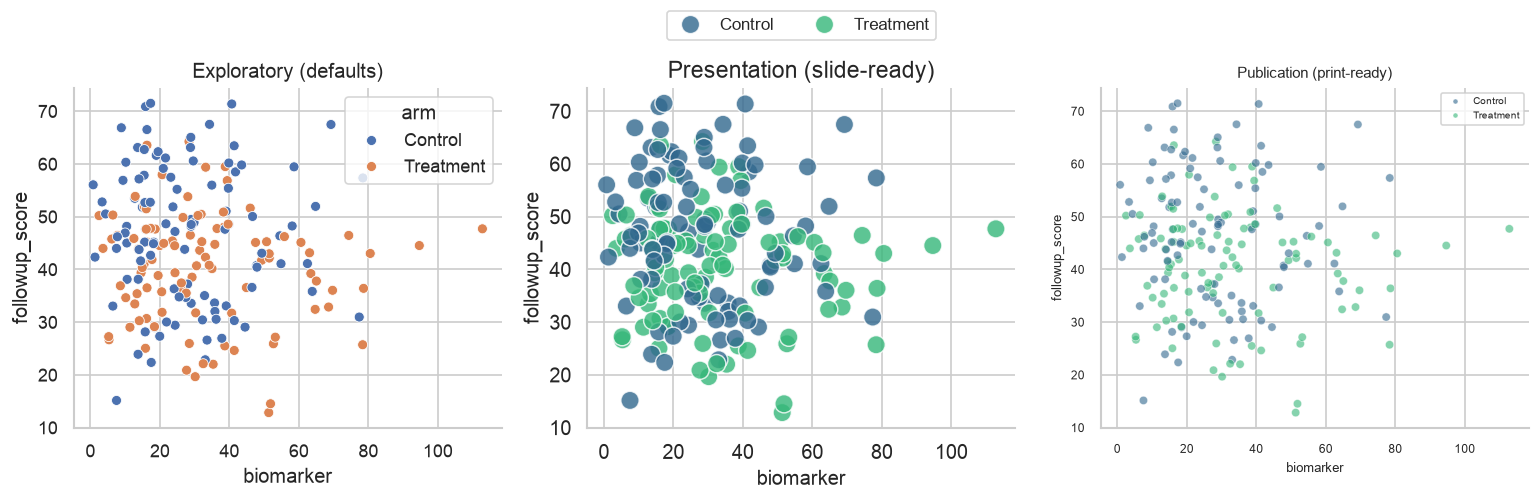

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

# Exploratory
sns.scatterplot(data=clinical_py, x="biomarker", y="followup_score", hue="arm", ax=axes[0])
axes[0].set_title("Exploratory (defaults)")

# Presentation
sns.scatterplot(data=clinical_py, x="biomarker", y="followup_score", hue="arm",
                 s=120, alpha=0.8, palette="viridis", ax=axes[1])
axes[1].set_title("Presentation (slide-ready)", fontsize=14)
axes[1].tick_params(labelsize=12)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=2, fontsize=10)

# Publication -- keeps a compact in-plot legend rather than dropping it entirely,
# since a reader otherwise has no way to know what each color means.
sns.scatterplot(data=clinical_py, x="biomarker", y="followup_score", hue="arm",
                 s=25, alpha=0.6, palette="viridis", ax=axes[2])
axes[2].set_title("Publication (print-ready)", fontsize=9)
axes[2].tick_params(labelsize=7)
axes[2].set_xlabel(axes[2].get_xlabel(), fontsize=8)
axes[2].set_ylabel(axes[2].get_ylabel(), fontsize=8)
axes[2].legend(fontsize=6, markerscale=0.6, title=None, loc="upper right", frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

**Note on the publication preset's legend:** some figures drop the legend entirely and rely on the caption instead. That's a legitimate space-saving technique, but it's a confusing default for a teaching example — a reader has no way to know what each color means without it. The publication preset above keeps a small, in-plot legend rather than removing it.

### A note on consistency across a paper

Define your preset once as a reusable function, and apply it everywhere:

```python
def apply_pub_style(ax, fontsize=9):
    ax.tick_params(labelsize=fontsize - 1)
    ax.set_xlabel(ax.get_xlabel(), fontsize=fontsize)
    ax.set_ylabel(ax.get_ylabel(), fontsize=fontsize)
    ax.set_title(ax.get_title(), fontsize=fontsize)
```

---

## 4. Table 1: Summary Statistics with Group Comparison Tests

- **Continuous variables**: t-test or Wilcoxon/Mann-Whitney
- **Categorical variables**: chi-square, or Fisher's exact when expected cell counts are small

### tableone

In [31]:
from tableone import TableOne

columns = ["age", "sex", "smoker", "biomarker", "response_label"]
categorical = ["sex", "smoker", "response_label"]

table1 = TableOne(
    clinical_py, columns=columns, categorical=categorical,
    groupby="arm", pval=True, htest_name=True
)

# Printed version
print(table1.tabulate(tablefmt="github"))

# DataFrame version with clean, flat column names (TableOne's .tableone has a
# MultiIndex on both rows and columns by default)
table1_raw = table1.tableone.copy()
table1_raw.index = table1_raw.index.set_names(["Characteristic", "Level"])
table1_df = table1_raw.reset_index()
table1_df.columns = [
    '_'.join([str(c) for c in col if c not in ('', 'Grouped by arm')]).strip('_')
    for col in table1_df.columns.to_flat_index()
]

# Styled HTML version -- renders as a rich table in Jupyter's output area.
# escape=True is important here: TableOne's p-value column often contains
# strings like "<0.001" (literal less-than sign, no space), which pandas'
# Styler would otherwise try to render as raw HTML -- interpreting it as
# the start of an HTML tag and breaking the display. escape=True forces
# those characters to be shown as plain text instead.
table1_df.style.set_caption("Baseline Characteristics by Arm").format(escape="html")

|                       |             |   Missing | Overall     | Control     | Treatment   | P-Value   | Test           |
|-----------------------|-------------|-----------|-------------|-------------|-------------|-----------|----------------|
| n                     |             |           | 200         | 100         | 100         |           |                |
| age, mean (SD)        |             |         0 | 58.2 (12.1) | 58.9 (12.6) | 57.6 (11.6) | 0.467     | Welch’s T-test |
| sex, n (%)            | Female      |           | 88 (44.0)   | 44 (44.0)   | 44 (44.0)   | 1.000     | Chi-squared    |
|                       | Male        |           | 112 (56.0)  | 56 (56.0)   | 56 (56.0)   |           |                |
| smoker, n (%)         | Current     |           | 41 (20.5)   | 17 (17.0)   | 24 (24.0)   | 0.077     | Chi-squared    |
|                       | Former      |           | 59 (29.5)   | 25 (25.0)   | 34 (34.0)   |           |                |
|               

,Characteristic,Level,Missing,Overall,Control,Treatment,P-Value,Test
0,n,,,200,100,100,,
1,"age, mean (SD)",,0,58.2 (12.1),58.9 (12.6),57.6 (11.6),0.467,Welch’s T-test
2,"sex, n (%)",Female,,88 (44.0),44 (44.0),44 (44.0),1.000,Chi-squared
3,"sex, n (%)",Male,,112 (56.0),56 (56.0),56 (56.0),,
4,"smoker, n (%)",Current,,41 (20.5),17 (17.0),24 (24.0),0.077,Chi-squared
5,"smoker, n (%)",Former,,59 (29.5),25 (25.0),34 (34.0),,
6,"smoker, n (%)",Never,,100 (50.0),58 (58.0),42 (42.0),,
7,"biomarker, mean (SD)",,0,30.5 (19.4),28.2 (17.1),32.9 (21.3),0.083,Welch’s T-test
8,"response_label, n (%)",No Response,,126 (63.0),77 (77.0),49 (49.0),<0.001,Chi-squared
9,"response_label, n (%)",Response,,74 (37.0),23 (23.0),51 (51.0),,


### Manual approach (explicit test selection + Fisher fallback)

In [32]:
from scipy.stats import ttest_ind, mannwhitneyu, chi2_contingency, fisher_exact

ctrl = clinical_py[clinical_py.arm == "Control"]
trt = clinical_py[clinical_py.arm == "Treatment"]

t_stat, t_p = ttest_ind(ctrl["age"], trt["age"])
u_stat, u_p = mannwhitneyu(ctrl["biomarker"], trt["biomarker"])

contingency = pd.crosstab(clinical_py["sex"], clinical_py["arm"])
chi2, chi_p, dof, expected = chi2_contingency(contingency)

if (expected < 5).any():
    odds_ratio, fisher_p = fisher_exact(contingency)
    test_used, p_value = "Fisher's exact", fisher_p
else:
    test_used, p_value = "Chi-square", chi_p

print(f"Age t-test p-value: {t_p:.4f}")
print(f"Biomarker Mann-Whitney p-value: {u_p:.4f}")
print(f"Sex test used: {test_used} - p-value: {p_value:.4f}")

Age t-test p-value: 0.4668
Biomarker Mann-Whitney p-value: 0.1818
Sex test used: Chi-square - p-value: 1.0000


---

## 5. Grammar of Graphics — Scatter Plot

**Teaching note:** sns.lmplot() fits a linear regression line through each group's points and, by default, shades a confidence band (shown as a lighter ribbon around the line) representing the uncertainty in that fitted line — typically a 95% confidence interval. The band is narrower where you have more data support (usually near the center of your x-values) and widens toward the edges, reflecting less certainty about the true relationship there. A narrow band suggests a well-estimated trend; a wide band is a visual cue to be cautious about over-interpreting the line, especially with small sample sizes per facet.

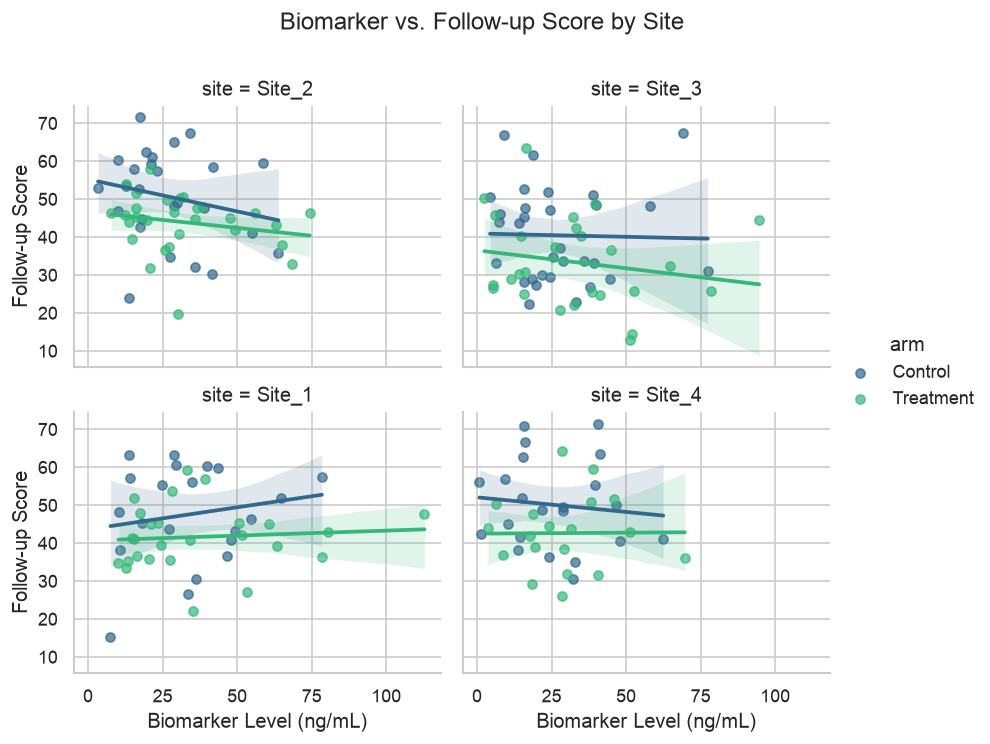

In [33]:
g = sns.lmplot(
    data=clinical_py, x="biomarker", y="followup_score",
    hue="arm", col="site", col_wrap=2,
    palette="viridis", height=3, aspect=1.2,
    scatter_kws={"alpha": 0.7, "s": 30}
)
g.set_axis_labels("Biomarker Level (ng/mL)", "Follow-up Score")
g.fig.suptitle("Biomarker vs. Follow-up Score by Site", y=1.03)
g.fig.subplots_adjust(top=0.90)
plt.show()

---

## 6. Line Chart — Longitudinal / Repeated Measures

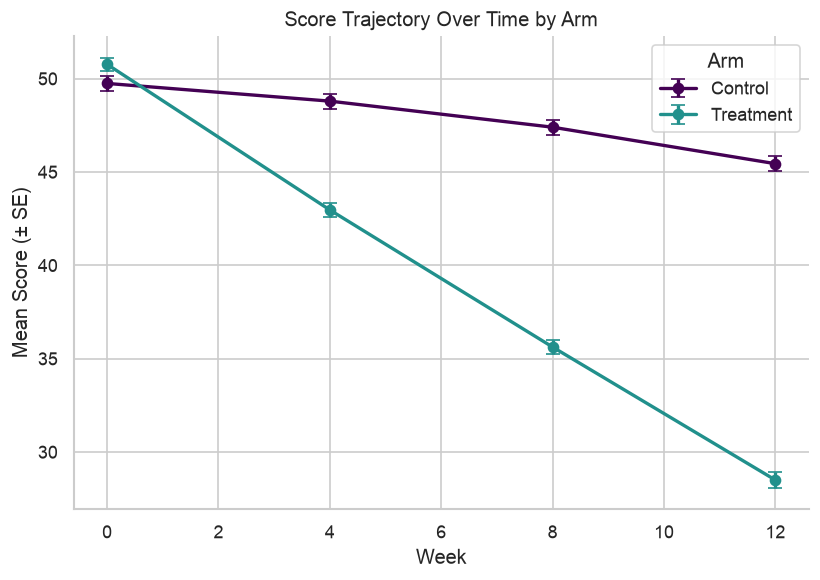

In [34]:
summary_py = (
    longitudinal_py.groupby(["arm", "week"])["score"]
    .agg(mean_score="mean", sd_score="std", n="count")
    .reset_index()
)
summary_py["se_score"] = summary_py["sd_score"] / np.sqrt(summary_py["n"])

fig, ax = plt.subplots(figsize=(7, 5))

for arm, color in colors.items():
    sub = summary_py[summary_py.arm == arm]
    ax.errorbar(sub["week"], sub["mean_score"], yerr=sub["se_score"],
                marker="o", capsize=4, label=arm, color=color, linewidth=2)

ax.set_xlabel("Week")
ax.set_ylabel("Mean Score (± SE)")
ax.set_title("Score Trajectory Over Time by Arm")
ax.legend(title="Arm")
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** SD describes spread of individual observations; SE describes uncertainty in the mean and shrinks as sample size grows. Always label which one you plotted.

---

## 7. Density Plots

### 7.1 Single density plot

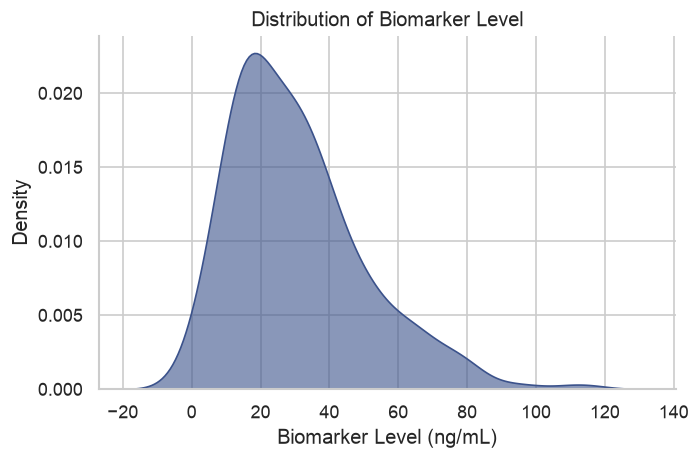

In [36]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=clinical_py, x="biomarker", fill=True, color="#3b528b", alpha=0.6, ax=ax)
ax.set_xlabel("Biomarker Level (ng/mL)")
ax.set_ylabel("Density")
ax.set_title("Distribution of Biomarker Level")
sns.despine()
plt.tight_layout()
plt.show()

### 7.2 Multiple-group overlaid density plot

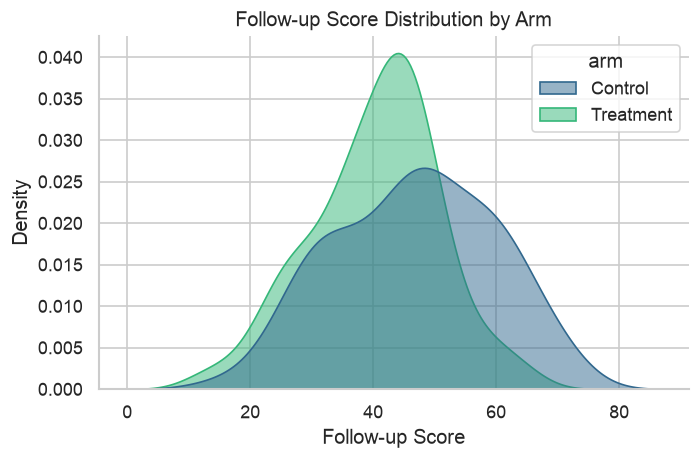

In [37]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=clinical_py, x="followup_score", hue="arm", fill=True,
            common_norm=False, alpha=0.5, palette="viridis", ax=ax)
ax.set_xlabel("Follow-up Score")
ax.set_ylabel("Density")
ax.set_title("Follow-up Score Distribution by Arm")
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** seaborn's `kdeplot()` defaults to `common_norm=True` (normalizes all groups jointly, so a larger group's curve looks taller). Setting `common_norm=False` makes each group's curve integrate to 1 independently, matching R's ggplot2 default — right when you want to compare *shape* regardless of group size.

### 7.3 Ridgeline plot (many groups)

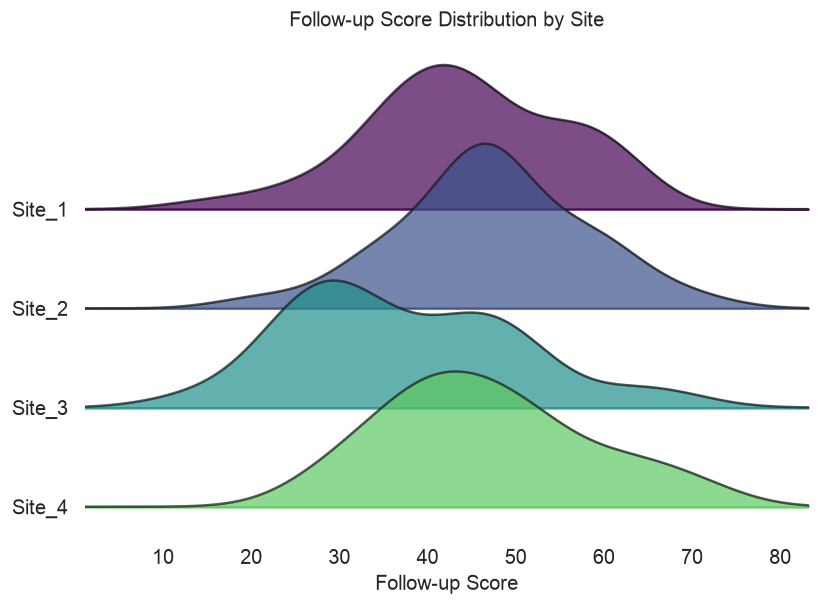

In [38]:
import joypy

fig, axes = joypy.joyplot(
    clinical_py, by="site", column="followup_score",
    colormap=plt.cm.viridis, alpha=0.7, figsize=(7, 5),
    title="Follow-up Score Distribution by Site"
)
plt.xlabel("Follow-up Score")
plt.show()

**Teaching note:** `joypy` is a thin, purpose-built wrapper for ridgeline plots in Python — there isn't a native seaborn/matplotlib equivalent. A fallback if `joypy` isn't available: `sns.FacetGrid(data, row="site").map(sns.kdeplot, "followup_score")` (not a true ridgeline, but similar information).

---

## 8. Kaplan-Meier Survival Curve

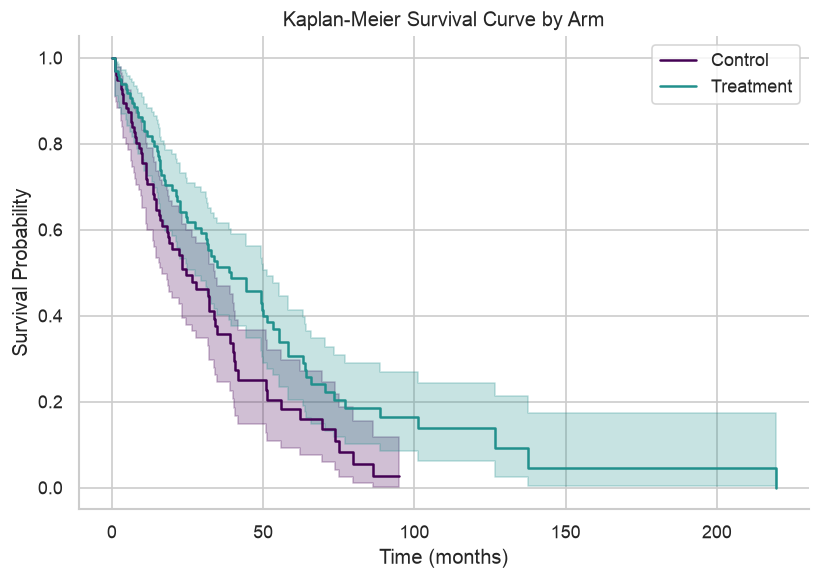

Log-rank p-value: 0.0104


In [39]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

fig, ax = plt.subplots(figsize=(7, 5))
kmf = KaplanMeierFitter()

for arm, color in colors.items():
    mask = clinical_py["arm"] == arm
    kmf.fit(clinical_py.loc[mask, "time_months"], clinical_py.loc[mask, "event"], label=arm)
    kmf.plot_survival_function(ax=ax, color=color, ci_show=True)

ax.set_xlabel("Time (months)")
ax.set_ylabel("Survival Probability")
ax.set_title("Kaplan-Meier Survival Curve by Arm")
sns.despine()
plt.tight_layout()
plt.show()

ctrl = clinical_py[clinical_py.arm == "Control"]
trt = clinical_py[clinical_py.arm == "Treatment"]
result = logrank_test(ctrl.time_months, trt.time_months,
                       event_observed_A=ctrl.event, event_observed_B=trt.event)
print(f"Log-rank p-value: {result.p_value:.4f}")

---

## 9. Forest Plot (Effect Sizes)

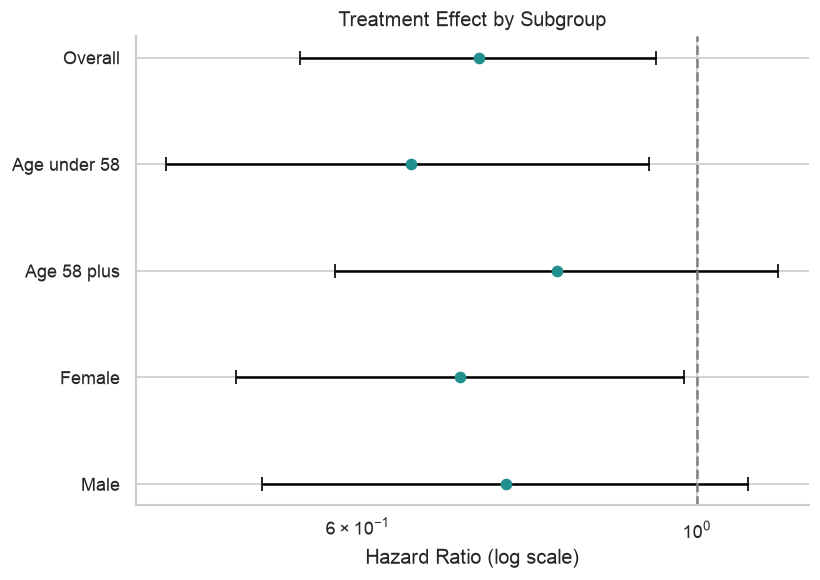

In [40]:
forest_data_py = pd.DataFrame({
    "subgroup": ["Overall", "Age under 58", "Age 58 plus", "Female", "Male"],
    "hr": [0.72, 0.65, 0.81, 0.70, 0.75],
    "lower": [0.55, 0.45, 0.58, 0.50, 0.52],
    "upper": [0.94, 0.93, 1.13, 0.98, 1.08],
})

fig, ax = plt.subplots(figsize=(7, 5))
y_pos = np.arange(len(forest_data_py))

ax.errorbar(
    forest_data_py["hr"], y_pos,
    xerr=[forest_data_py["hr"] - forest_data_py["lower"],
          forest_data_py["upper"] - forest_data_py["hr"]],
    fmt="o", color="#21908C", ecolor="black", capsize=4
)
ax.axvline(x=1, linestyle="--", color="gray")
ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(forest_data_py["subgroup"])
ax.invert_yaxis()
ax.set_xlabel("Hazard Ratio (log scale)")
ax.set_title("Treatment Effect by Subgroup")
sns.despine()
plt.tight_layout()
plt.show()

Hazard ratios are plotted on a log scale so that a doubling (HR=2) and a halving (HR=0.5) of risk sit at equal visual distances from the null line at HR=1.

---

## 10. ROC Curve and AUC

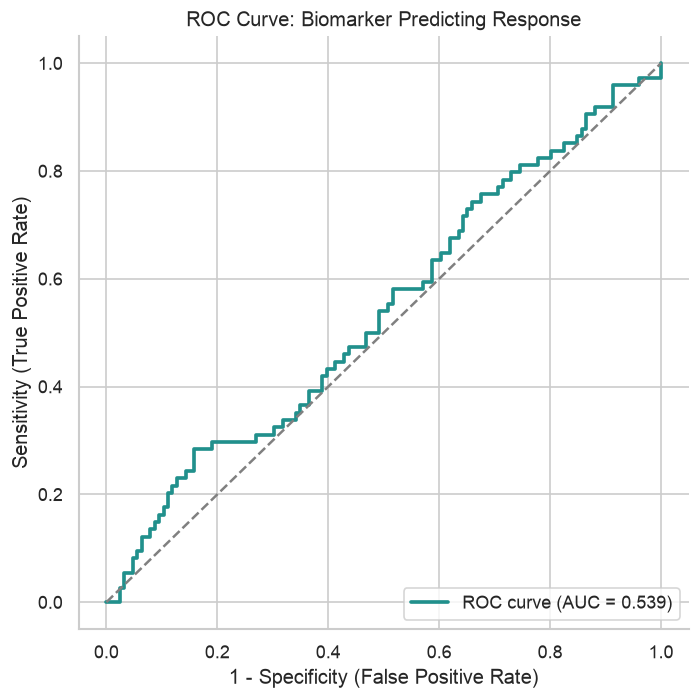

In [42]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(clinical_py["responder"], clinical_py["biomarker"])
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color="#21908C", linewidth=2.2, label=f"ROC curve (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("1 - Specificity (False Positive Rate)")
ax.set_ylabel("Sensitivity (True Positive Rate)")
ax.set_title("ROC Curve: Biomarker Predicting Response")
ax.legend(loc="lower right")
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** AUC alone doesn't tell you where to set a decision threshold for clinical use — that requires weighing the relative cost of false positives vs. false negatives in your specific clinical context.

---

## 11. Boxplot Variants with Statistical Annotation

### 11.1 Boxplot with jitter

Control vs. Treatment: Mann-Whitney-Wilcoxon test two-sided, P_val:3.208e-04 U_stat=6.473e+03


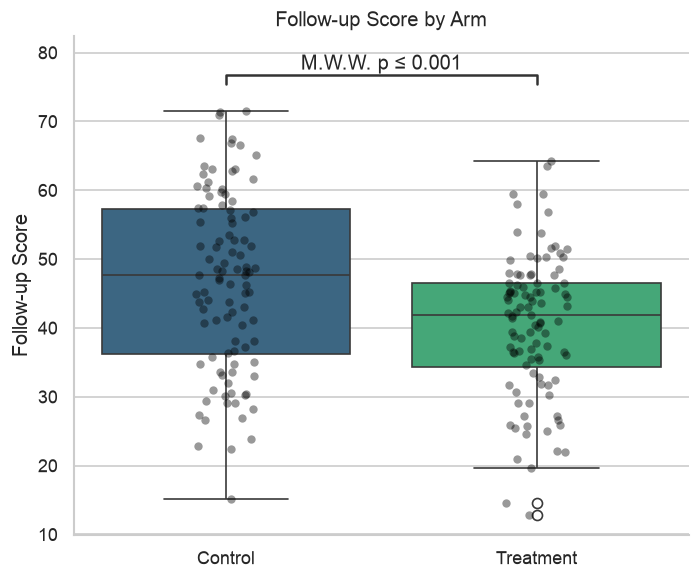

In [45]:
try:
    from statannotations.Annotator import Annotator
    HAS_STATANNOTATIONS = True
except ImportError:
    HAS_STATANNOTATIONS = False

fig, ax = plt.subplots(figsize=(6, 5))
order = ["Control", "Treatment"]

sns.boxplot(data=clinical_py, x="arm", y="followup_score", order=order, hue="arm", palette="viridis", legend=False, ax=ax)
sns.stripplot(data=clinical_py, x="arm", y="followup_score", order=order, color="black", alpha=0.4, ax=ax)

if HAS_STATANNOTATIONS:
    # M.W.W. = Mann-Whitney-Wilcoxon (statannotations' label for this test)
    annotator = Annotator(ax, [("Control", "Treatment")],
                           data=clinical_py, x="arm", y="followup_score", order=order)
    annotator.configure(test="Mann-Whitney", text_format="simple")
    annotator.apply_and_annotate()
else:
    from scipy.stats import mannwhitneyu
    grp_control = clinical_py.loc[clinical_py.arm == "Control", "followup_score"]
    grp_treatment = clinical_py.loc[clinical_py.arm == "Treatment", "followup_score"]
    stat, p_val = mannwhitneyu(grp_control, grp_treatment, alternative="two-sided")
    p_label = f"p = {p_val:.4f}" if p_val >= 0.0001 else "p < 0.0001"
    y_max = clinical_py["followup_score"].max()
    y_range = clinical_py["followup_score"].max() - clinical_py["followup_score"].min()
    bar_y = y_max + 0.05 * y_range
    text_y = bar_y + 0.02 * y_range
    ax.plot([0, 0, 1, 1], [bar_y, bar_y + 0.01 * y_range, bar_y + 0.01 * y_range, bar_y], lw=1.2, color="black")
    ax.text(0.5, text_y, p_label, ha="center", va="bottom", fontsize=10)
    ax.set_ylim(top=text_y + 0.08 * y_range)

ax.set_xlabel(None)
ax.set_ylabel("Follow-up Score")
ax.set_title("Follow-up Score by Arm")
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** if `statannotations` fails to import, the `try/except` above falls back to a manual Mann-Whitney test with a hand-drawn bracket — same statistical result, no extra dependency.

### 11.2 Mean ± SD bar chart with significance stars

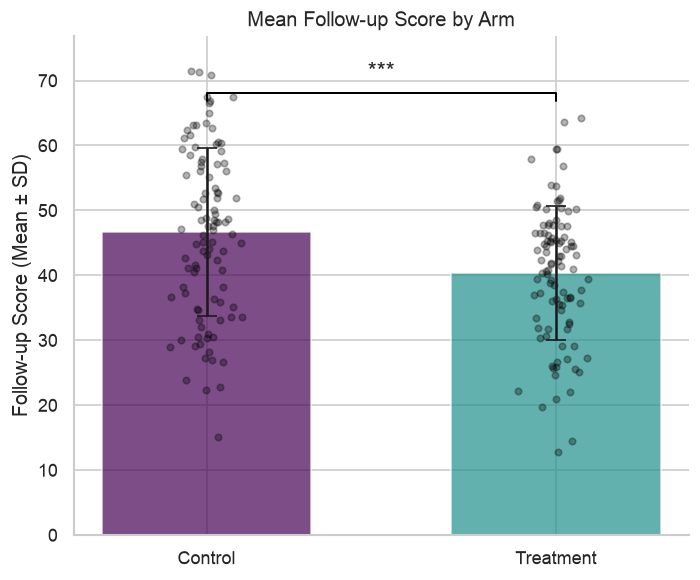

In [46]:
from scipy.stats import mannwhitneyu

summary_stats_py = (
    clinical_py.groupby("arm")["followup_score"]
    .agg(mean_val="mean", sd_val="std")
    .reset_index()
)

grp_control = clinical_py.loc[clinical_py.arm == "Control", "followup_score"]
grp_treatment = clinical_py.loc[clinical_py.arm == "Treatment", "followup_score"]
stat, p_val = mannwhitneyu(grp_control, grp_treatment, alternative="two-sided")

def p_to_stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

stars_py = p_to_stars(p_val)

fig, ax = plt.subplots(figsize=(6, 5))
x_pos = np.arange(len(summary_stats_py))

ax.bar(x_pos, summary_stats_py["mean_val"], yerr=summary_stats_py["sd_val"], capsize=6,
       color=["#440154", "#21908C"], alpha=0.7, width=0.6)

for i, arm in enumerate(summary_stats_py["arm"]):
    vals = clinical_py.loc[clinical_py.arm == arm, "followup_score"]
    jitter = np.random.normal(0, 0.04, size=len(vals))
    ax.scatter(np.full(len(vals), i) + jitter, vals, color="black", alpha=0.3, s=15)

y_bracket = (summary_stats_py["mean_val"] + summary_stats_py["sd_val"]).max() * 1.12
ax.plot([0, 0, 1, 1], [y_bracket, y_bracket*1.02, y_bracket*1.02, y_bracket], lw=1.2, color="black")
ax.text(0.5, y_bracket * 1.04, stars_py, ha="center", va="bottom", fontsize=14)

ax.set_xticks(x_pos)
ax.set_xticklabels(summary_stats_py["arm"])
ax.set_ylabel("Follow-up Score (Mean ± SD)")
ax.set_title("Mean Follow-up Score by Arm")
_ = ax.set_ylim(top=y_bracket * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

Thresholds: `*` p<0.05, `**` p<0.01, `***` p<0.001, `ns` not significant. State these explicitly in your figure legend.

### 11.3 Three-group bar chart with ANOVA + pairwise comparisons

**Note on the synthetic data:** `Site_3` has a deliberately engineered lower average `followup_score` baked into Section 1's data generation, so this example has something significant to find. In your own real data you won't know the answer in advance.

ANOVA p-value: 0.0000
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
Site_1 Site_2   2.8096 0.6055  -3.0859  8.7051  False
Site_1 Site_3  -7.0357 0.0112 -12.8833  -1.188   True
Site_1 Site_4    2.368 0.7681  -3.9744  8.7103  False
Site_2 Site_3  -9.8452 0.0001  -15.455 -4.2355   True
Site_2 Site_4  -0.4416 0.9977  -6.5653  5.6821  False
Site_3 Site_4   9.4037 0.0005    3.326 15.4813   True
-----------------------------------------------------


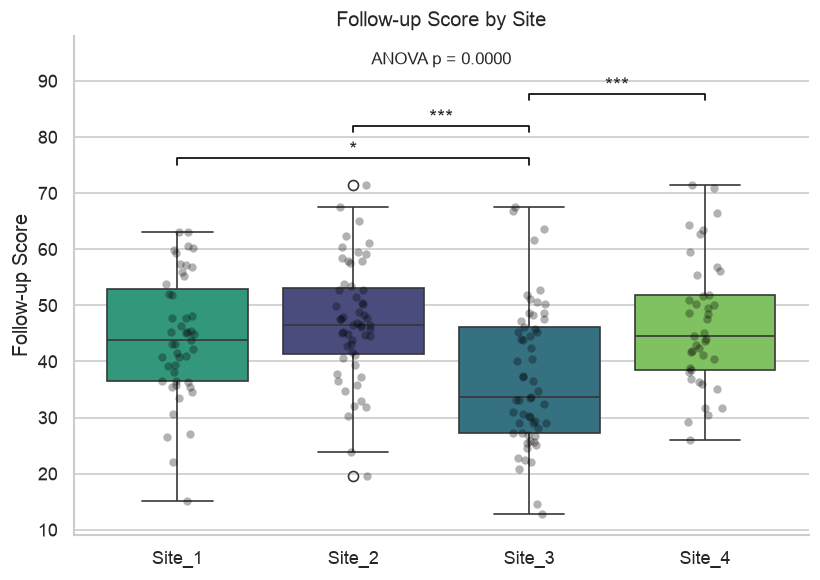

In [48]:
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sites = sorted(clinical_py["site"].unique())
site_groups = [clinical_py.loc[clinical_py.site == s, "followup_score"] for s in sites]

f_stat, anova_p = f_oneway(*site_groups)
print(f"ANOVA p-value: {anova_p:.4f}")

tukey = pairwise_tukeyhsd(endog=clinical_py["followup_score"], groups=clinical_py["site"], alpha=0.05)
print(tukey.summary())

tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])

def p_to_stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return None

fig, ax = plt.subplots(figsize=(7, 5))
order = sites

sns.boxplot(data=clinical_py, x="site", y="followup_score", order=order, hue="site", palette="viridis", legend=False, ax=ax)
sns.stripplot(data=clinical_py, x="site", y="followup_score", order=order, color="black", alpha=0.3, ax=ax)

y_max = clinical_py["followup_score"].max()
ax.text((len(order) - 1) / 2, y_max * 1.3, f"ANOVA p = {anova_p:.4f}", ha="center", fontsize=10)

bracket_y = y_max * 1.05
step = y_max * 0.08
for _, row in tukey_df.iterrows():
    stars = p_to_stars(row["p-adj"])
    if stars is None:
        continue
    i, j = order.index(row["group1"]), order.index(row["group2"])
    ax.plot([i, i, j, j], [bracket_y, bracket_y+step*0.2, bracket_y+step*0.2, bracket_y], lw=1, color="black")
    ax.text((i+j)/2, bracket_y + step*0.25, stars, ha="center", fontsize=12)
    bracket_y += step

_ = ax.set_xlabel(None)
_ = ax.set_ylabel("Follow-up Score")
_ = ax.set_title("Follow-up Score by Site")
_ = ax.set_ylim(top=bracket_y + step)
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** `pairwise_tukeyhsd` already applies the Tukey correction for multiple comparisons, so `row["p-adj"]` is safe to use directly for star thresholds.

---

## 12. Stacked Bar Plot (Categorical Proportions)

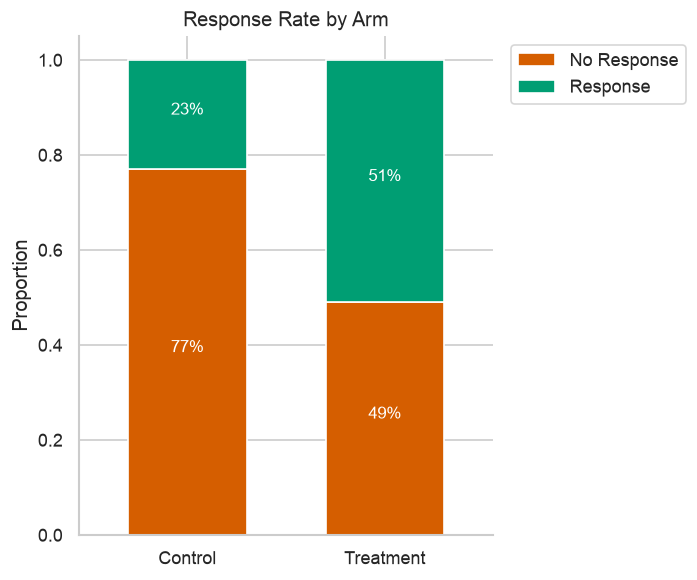

In [49]:
response_summary_py = (
    clinical_py.groupby(["arm", "response_label"]).size()
    .unstack()
)
response_summary_py = response_summary_py.div(response_summary_py.sum(axis=1), axis=0)

okabe_ito_pair = ["#D55E00", "#009E73"]
fig, ax = plt.subplots(figsize=(6, 5))
response_summary_py.plot(kind="bar", stacked=True, color=okabe_ito_pair, ax=ax, width=0.6)

for i, arm in enumerate(response_summary_py.index):
    cumulative = 0
    for col in response_summary_py.columns:
        val = response_summary_py.loc[arm, col]
        _ = ax.text(i, cumulative + val / 2, f"{val:.0%}", ha="center", color="white", fontsize=10)
        cumulative += val

_ = ax.set_xlabel(None)
_ = ax.set_ylabel("Proportion")
_ = ax.set_title("Response Rate by Arm")
_ = ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
_ = ax.set_xticklabels(response_summary_py.index, rotation=0)
sns.despine()
plt.tight_layout()
plt.show()

**Teaching note:** stacked bars are fine for 2-3 categories with a clear ordering. For more than ~4 categories, consider a grouped bar chart instead.

---

## 13. PCA: Principal Component Plot and Biplot

In [50]:
np.random.seed(7)
n_biomarkers = 6
biomarker_cols = [f"marker_{i}" for i in range(1, n_biomarkers + 1)]

latent_factor = np.random.normal(0, 1, n)
arm_shift = np.where(clinical_py["arm"] == "Treatment", 1.2, -1.2)

pca_data_py = clinical_py[["patient_id", "arm", "site"]].copy()
for col in biomarker_cols:
    pca_data_py[col] = (
        latent_factor * np.random.uniform(0.4, 0.9)
        + arm_shift * np.random.uniform(0.2, 0.6)
        + np.random.normal(0, 1, n)
    )

pca_data_py.to_csv("pca_data.csv", index=False)
pca_data_py.head()

,patient_id,arm,site,marker_1,marker_2,marker_3,marker_4,marker_5,marker_6
0,PT-001,Control,Site_2,-0.661422,0.959067,1.423010,0.180452,1.477812,0.210582
1,PT-002,Treatment,Site_3,-1.267603,-1.591697,1.731018,0.402519,-1.139939,0.109130
2,PT-003,Control,Site_1,-0.740499,1.011274,-0.808125,-0.503459,-0.955171,-0.460009
3,PT-004,Control,Site_1,0.671635,-0.771044,1.320812,-0.343390,-0.050152,1.038581
4,PT-005,Control,Site_4,-0.653223,-0.211003,-0.701481,-1.231805,-0.700926,-0.111444


### PC score plot

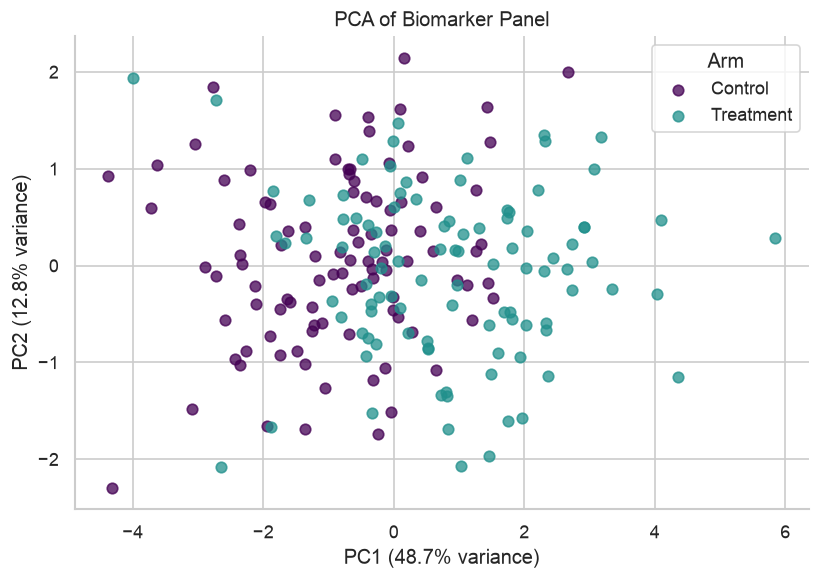

In [51]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = pca_data_py[biomarker_cols].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
pc_scores = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_ * 100

pc_df = pd.DataFrame(pc_scores, columns=["PC1", "PC2"])
pc_df["arm"] = pca_data_py["arm"].values

fig, ax = plt.subplots(figsize=(7, 5))
for arm_name, color in colors.items():
    sub = pc_df[pc_df.arm == arm_name]
    ax.scatter(sub["PC1"], sub["PC2"], color=color, alpha=0.75, s=40, label=arm_name)

_ = ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
_ = ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
_ = ax.set_title("PCA of Biomarker Panel")
ax.legend(title="Arm")
sns.despine()
plt.tight_layout()
plt.show()

Scaling (`StandardScaler`) matters for PCA — without it, biomarkers on larger numeric scales dominate the components purely due to units.

### Biplot

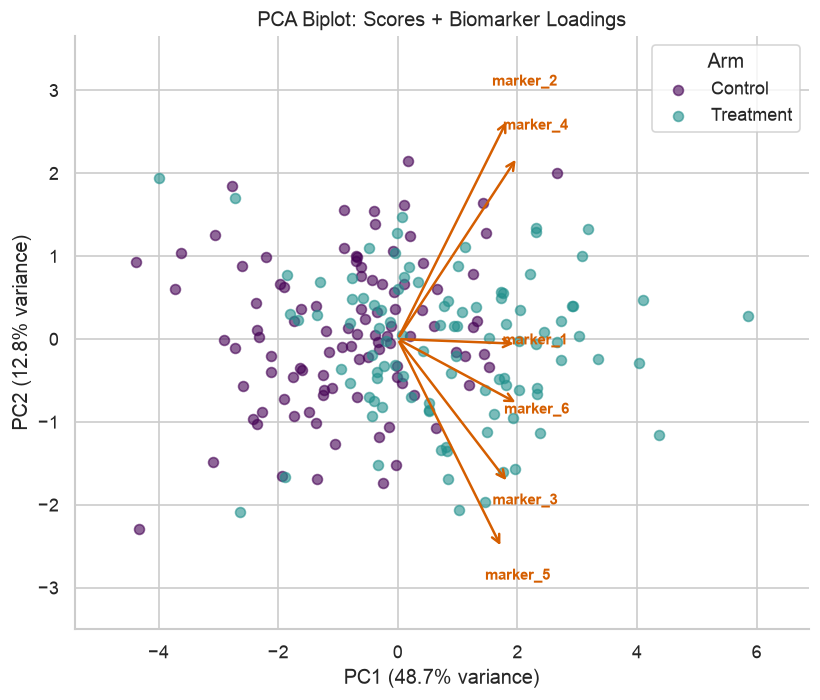

In [52]:
loadings = pca.components_.T[:, :2]
scale_factor = np.abs(pc_scores).max() * 0.8

fig, ax = plt.subplots(figsize=(7, 6))

for arm_name, color in colors.items():
    sub = pc_df[pc_df.arm == arm_name]
    ax.scatter(sub["PC1"], sub["PC2"], color=color, alpha=0.6, s=35, label=arm_name)

arrow_endpoints_x = []
arrow_endpoints_y = []

for i, marker_name in enumerate(biomarker_cols):
    x_end = loadings[i, 0] * scale_factor
    y_end = loadings[i, 1] * scale_factor

    ax.annotate("", xy=(x_end, y_end), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.5))
    label_x, label_y = x_end * 1.15, y_end * 1.15
    ax.text(label_x, label_y, marker_name, color="#D55E00", fontsize=9, fontweight="bold", ha="center")

    arrow_endpoints_x.append(label_x)
    arrow_endpoints_y.append(label_y)

all_x = list(pc_df["PC1"]) + arrow_endpoints_x
all_y = list(pc_df["PC2"]) + arrow_endpoints_y
x_margin = (max(all_x) - min(all_x)) * 0.1
y_margin = (max(all_y) - min(all_y)) * 0.1
_ = ax.set_xlim(min(all_x) - x_margin, max(all_x) + x_margin)
_ = ax.set_ylim(min(all_y) - y_margin, max(all_y) + y_margin)

_ = ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
_ = ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
_ = ax.set_title("PCA Biplot: Scores + Biomarker Loadings")
ax.legend(title="Arm")
sns.despine()
plt.tight_layout()
plt.show()

Arrow direction shows which PCs a variable contributes to; arrow length shows how strongly. Same direction = positively correlated; opposite = negatively correlated; ~90 degrees apart = little correlation.

### Scree plot

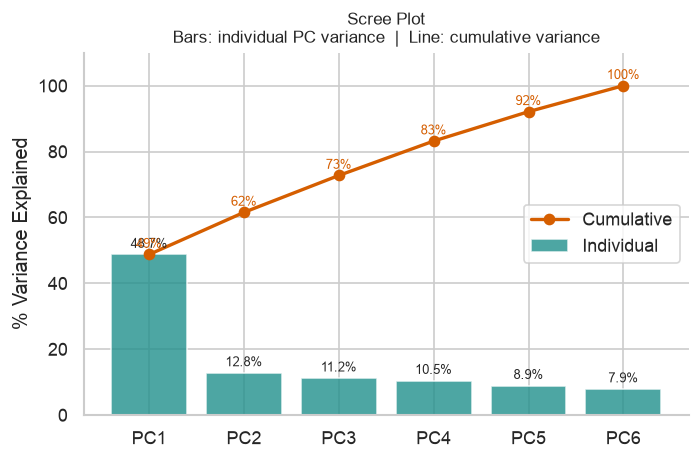

In [53]:
pca_full = PCA().fit(X_scaled)
var_explained_full = pca_full.explained_variance_ratio_ * 100
cumulative_full = np.cumsum(var_explained_full)

fig, ax = plt.subplots(figsize=(6, 4))
pcs = [f"PC{i+1}" for i in range(len(var_explained_full))]
ax.bar(pcs, var_explained_full, color="#21908C", alpha=0.8, label="Individual")
ax.plot(pcs, cumulative_full, color="#D55E00", marker="o", linewidth=2, label="Cumulative")

for i, v in enumerate(var_explained_full):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center", fontsize=8)
for i, v in enumerate(cumulative_full):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color="#D55E00")

_ = ax.set_ylabel("% Variance Explained")
_ = ax.set_title("Scree Plot\nBars: individual PC variance  |  Line: cumulative variance", fontsize=10)
_ = ax.set_ylim(0, 110)
ax.legend(loc="center right")
sns.despine()
plt.tight_layout()
plt.show()

### PCA notes

- Always report % variance explained in the axis label
- Color points by a meaningful metadata variable (condition, batch, cell type)
- For batch-effect checks, plot PCA colored by batch separately from biological condition
- A scree plot helps judge how many PCs actually matter

---

## 14. Multi-Panel Publication Figure

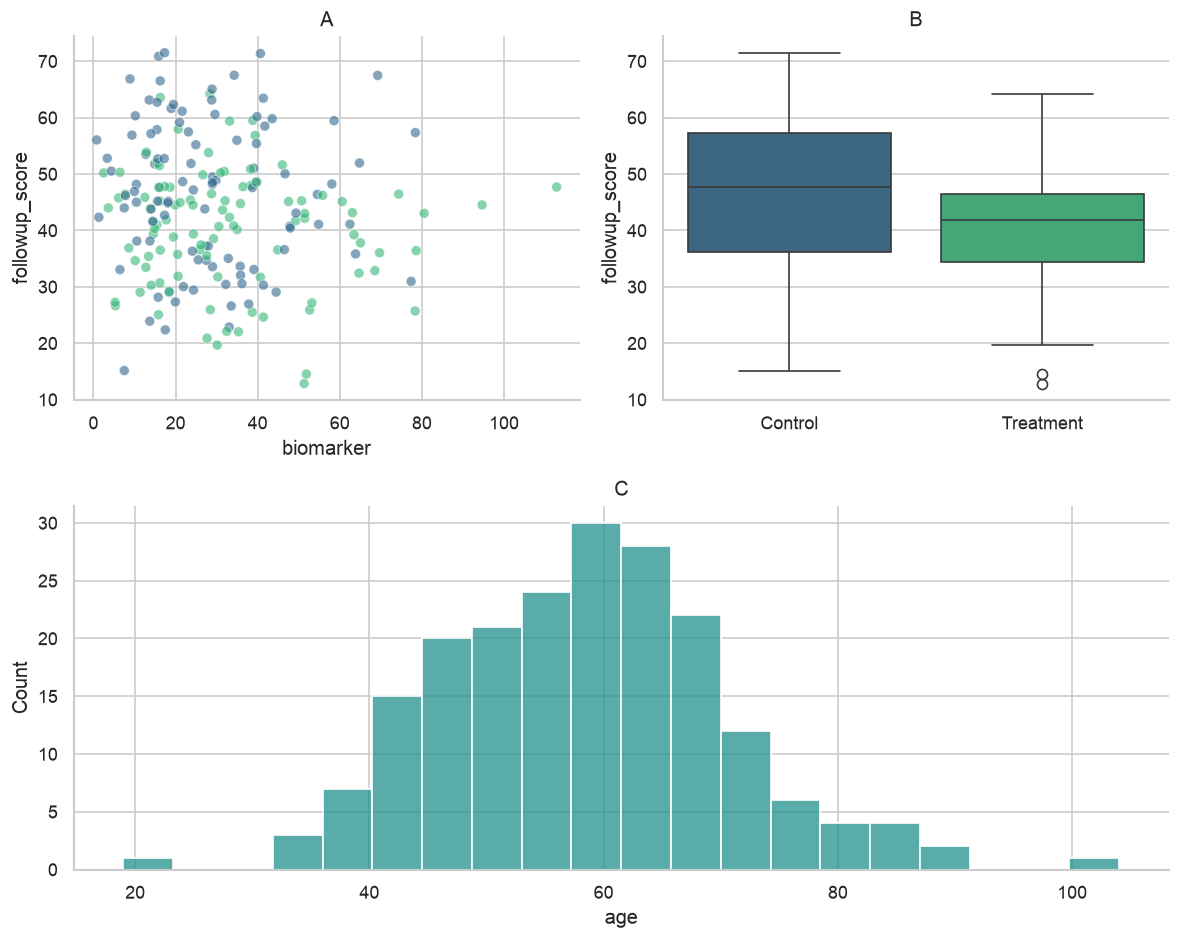

In [57]:
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
sns.scatterplot(data=clinical_py, x="biomarker", y="followup_score", hue="arm",
                 palette="viridis", alpha=0.6, ax=ax1, legend=False)
_ = ax1.set_title("A")

ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(data=clinical_py, x="arm", y="followup_score", hue="arm", palette="viridis", legend=False, ax=ax2)
_ = ax2.set_title("B")
_ = ax2.set_xlabel(None)

ax3 = fig.add_subplot(gs[1, :])
sns.histplot(data=clinical_py, x="age", bins=20, color="#21908C", ax=ax3)
_ = ax3.set_title("C")

sns.despine()
plt.tight_layout()
plt.show()

---

## 15. Exporting for Publication

In [58]:
# Vector format (preferred for line art / simple figures)
fig.savefig("figure1_km_curve.pdf", dpi=300, bbox_inches="tight")

# Raster format (needed for dense scatter plots, images, some journal requirements)
fig.savefig("figure1_km_curve.tiff", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})

---

## 16. Practice Exercise (20 min)

Using `clinical_trial_data.csv`, `longitudinal_data.csv`, and `pca_data.csv`, pick **one** and build a publication-ready version:

1. A Table 1 comparing baseline characteristics by arm
2. A density plot or ridgeline plot comparing a continuous variable across groups
3. A Kaplan-Meier curve comparing arms, with a risk table
4. A forest plot showing hazard ratios across 3+ subgroups
5. An ROC curve with AUC for biomarker predicting responder status
6. A line chart of score trajectory over time by arm
7. An annotated boxplot/mean±SD bar (with significance stars) comparing scores across site
8. A stacked bar chart of smoker status composition by site
9. A PCA score plot or biplot of the biomarker panel

**Checklist:**

- [ ] Colorblind-safe palette
- [ ] Axis labels with units
- [ ] Consistent theme
- [ ] Correct statistical test for the variable type
- [ ] Exported at 300 DPI in both PDF and PNG/TIFF

---

## Appendix: Color Palette Sources

### Viridis

Designed by Stéfan van der Walt and Nathaniel Smith for matplotlib in 2015; became matplotlib's default colormap in version 2.0. Perceptually uniform, monotonically increasing luminance, legible under common color vision deficiencies. Python: built into matplotlib/seaborn via `palette="viridis"` or `cmap="viridis"`.

### Okabe-Ito

Proposed by Masataka Okabe and Kei Ito (2008), "Color Universal Design." An empirically-chosen 8-color qualitative palette distinguishable across common forms of color blindness. Popularized by Bang Wong's 2011 Nature Methods commentary (doi:10.1038/nmeth.1618). Python has no built-in name — define manually:

```python
okabe_ito = ['#E69F00', '#56B4E9', '#009E73', '#F0E442',
             '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=okabe_ito)
# or: sns.set_palette(okabe_ito)
```

**Rule of thumb:** viridis for continuous data, Okabe-Ito for categorical data.